# Qué se ha hecho:
- Carga y revisión de datos: se trabajó con clientes_segmentados_k6.csv, compuesto por 498.863 clientes y las etiquetas del modelo original.
- Caracterización de los seis clústeres originales (Cluster_K6): se analizó el tamaño de cada segmento, su porcentaje sobre el total, la antigüedad, el número de contratos y las variables relacionadas con el suministro.
- Análisis de la composición de los segmentos: se examinó la distribución de los clientes de Solo Luz, Solo Gas y Dual entre los seis clústeres.
- Identificación de diferencias relevantes: se observaron diferencias de antigüedad entre C0 y C3, ambos formados por clientes de Solo Luz, así como diferencias en el número medio de contratos entre C1 y C4, ambos compuestos por clientes Dual.
- Identificación de casos que requerían cautela: se observó que C5 presentaba una media de 2,41 contratos y una mayor diversidad de potencias contratadas. Estos resultados se consideraron descriptivos, sin atribuirles directamente mayor rentabilidad ni incidencias técnicas.
- Análisis de sensibilidad A: se entrenó un segundo modelo K-Means con \(K=6\), utilizando únicamente Antiguedad_Meses y Num_Contratos, tras aplicar la transformación log1p al número de contratos y estandarizar ambas variables.
- Evaluación del modelo alternativo: se obtuvo un coeficiente Silhouette de 0,6466, calculado sobre una muestra de 20.000 clientes, y se compararon las nuevas etiquetas con Cluster_K6.
- Comprobación de consistencia: se verificaron los tamaños de los nuevos clústeres, las frecuencias del número de contratos y el cruce entre ambas segmentaciones.
- Conclusión metodológica: se observó que la segmentación cambiaba al excluir las variables de suministro. Se mantuvo el modelo original como modelo principal del TFM y se consideró la prueba de sensibilidad como análisis complementario.

# TFM - Fase 7: Caracterización e Interpretación de Clústeres
## Validación Inicial de `clientes_segmentados_k6.csv`

In [5]:
import pandas as pd
import os

# 1. Cargar el CSV
csv_path = 'clientes_segmentados_k6.csv'
if os.path.exists(csv_path):
    df_clientes_segmentados = pd.read_csv(csv_path)
    print("[OK] Archivo 'clientes_segmentados_k6.csv' cargado exitosamente en 'df_clientes_segmentados'.")
else:
    print("[ERROR] No se encuentra el archivo 'clientes_segmentados_k6.csv' en el directorio de trabajo.")

[OK] Archivo 'clientes_segmentados_k6.csv' cargado exitosamente en 'df_clientes_segmentados'.


In [6]:
# 2. Dimensiones, nombres y tipos de datos
print(f"Dimensiones: {df_clientes_segmentados.shape[0]} filas y {df_clientes_segmentados.shape[1]} columnas.\n")
print("Estructura y tipos de datos:")
df_clientes_segmentados.info()

Dimensiones: 498863 filas y 12 columnas.

Estructura y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 498863 entries, 0 to 498862
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Num Cliente                  498863 non-null  int64  
 1   Num_Productos                498863 non-null  int64  
 2   Num_Contratos                498863 non-null  int64  
 3   Fecha_Primera_Creacion       498863 non-null  object 
 4   Tiene_Luz                    498863 non-null  int64  
 5   Tiene_Gas                    498863 non-null  int64  
 6   Clasificacion_Suministro     498863 non-null  object 
 7   Conflicto_Tipo_Cliente       498863 non-null  int64  
 8   Antiguedad_Meses             498863 non-null  float64
 9   Num_Potencias_Distintas      498863 non-null  int64  
 10  Num_Escalones_Gas_Distintos  498863 non-null  int64  
 11  Cluster_K6                   498863 non-null  

In [7]:
# 3. Comprobación de duplicados y nulos en 'Num Cliente'
total_filas = len(df_clientes_segmentados)
duplicados_id = df_clientes_segmentados['Num Cliente'].duplicated().sum()
nulos_id = df_clientes_segmentados['Num Cliente'].isnull().sum()

print(f"Total de registros: {total_filas}")
print(f"Identificadores 'Num Cliente' duplicados: {duplicados_id}")
print(f"Identificadores 'Num Cliente' nulos: {nulos_id}")
if duplicados_id == 0 and nulos_id == 0:
    print("[CONFIRMADO] La variable 'Num Cliente' actúa correctamente como clave primaria única y limpia.")

Total de registros: 498863
Identificadores 'Num Cliente' duplicados: 0
Identificadores 'Num Cliente' nulos: 0
[CONFIRMADO] La variable 'Num Cliente' actúa correctamente como clave primaria única y limpia.


In [8]:
# 4 & 5. Verificación de clústeres y su distribución
print("--- Distribución de Clústeres (Cluster_K6) ---")
nulos_cluster = df_clientes_segmentados['Cluster_K6'].isnull().sum()
print(f"Valores nulos en 'Cluster_K6': {nulos_cluster}\n")

# Conteo y Porcentaje
cluster_counts = df_clientes_segmentados['Cluster_K6'].value_counts(dropna=False).sort_index()
cluster_pcts = df_clientes_segmentados['Cluster_K6'].value_counts(normalize=True, dropna=False).sort_index() * 100

dist_df = pd.DataFrame({
    'Clientes (N)': cluster_counts,
    'Porcentaje (%)': cluster_pcts
})
display(dist_df)

--- Distribución de Clústeres (Cluster_K6) ---
Valores nulos en 'Cluster_K6': 0



,Clientes (N),Porcentaje (%)
Cluster_K6,,
0,84100,16.858336
1,77927,15.620922
2,20047,4.018538
3,255561,51.228694
4,33932,6.801867
5,27296,5.471643


In [9]:
# 6. Distribución de 'Clasificacion_Suministro' dentro de cada clúster
if 'Clasificacion_Suministro' in df_clientes_segmentados.columns:
    print("--- Distribución Absoluta de 'Clasificacion_Suministro' por Clúster ---")
    suministro_abs = pd.crosstab(df_clientes_segmentados['Cluster_K6'], df_clientes_segmentados['Clasificacion_Suministro'], margins=True)
    display(suministro_abs)

    print("\n--- Distribución Porcentual (por clúster, horizontal) ---")
    suministro_pct = pd.crosstab(df_clientes_segmentados['Cluster_K6'], df_clientes_segmentados['Clasificacion_Suministro'], normalize='index') * 100
    display(suministro_pct.round(2))
else:
    print("[ALERTA] La columna 'Clasificacion_Suministro' no se encuentra en el DataFrame.")

--- Distribución Absoluta de 'Clasificacion_Suministro' por Clúster ---


Clasificacion_Suministro,Dual,Solo Gas,Solo Luz,All
Cluster_K6,,,,
0,0,0,84100,84100
1,77927,0,0,77927
2,0,20047,0,20047
3,0,0,255561,255561
4,33932,0,0,33932
5,2,2,27292,27296
All,111861,20049,366953,498863



--- Distribución Porcentual (por clúster, horizontal) ---


Clasificacion_Suministro,Dual,Solo Gas,Solo Luz
Cluster_K6,,,
0,0.00,0.00,100.00
1,100.00,0.00,0.00
2,0.00,100.00,0.00
3,0.00,0.00,100.00
4,100.00,0.00,0.00
5,0.01,0.01,99.99


In [10]:
# 7. Identificación de variables disponibles para caracterizar
print("--- Variables disponibles para caracterización ---")
columnas_candidatas = [col for col in df_clientes_segmentados.columns if col not in ['Num Cliente', 'Cluster_K6']]
for col in columnas_candidatas:
    print(f"- {col} (Tipo: {df_clientes_segmentados[col].dtype})")

--- Variables disponibles para caracterización ---
- Num_Productos (Tipo: int64)
- Num_Contratos (Tipo: int64)
- Fecha_Primera_Creacion (Tipo: object)
- Tiene_Luz (Tipo: int64)
- Tiene_Gas (Tipo: int64)
- Clasificacion_Suministro (Tipo: object)
- Conflicto_Tipo_Cliente (Tipo: int64)
- Antiguedad_Meses (Tipo: float64)
- Num_Potencias_Distintas (Tipo: int64)
- Num_Escalones_Gas_Distintos (Tipo: int64)


# Caracterización Estadística de los Clústeres
En esta sección se calculan las estadísticas descriptivas necesarias para perfilar matemáticamente los seis segmentos obtenidos.

In [11]:
# 1. Tamaño de los segmentos
total_clientes = len(df_clientes_segmentados)
tamano_clusters = df_clientes_segmentados['Cluster_K6'].value_counts().sort_index()
porcentaje_clusters = (tamano_clusters / total_clientes) * 100

resumen_tamano = pd.DataFrame({
    'Clientes (N)': tamano_clusters,
    'Porcentaje (%)': porcentaje_clusters
})
print("=== Tamaño de los Segmentos ===")
display(resumen_tamano.round(4))

=== Tamaño de los Segmentos ===


,Clientes (N),Porcentaje (%)
Cluster_K6,,
0,84100,16.8583
1,77927,15.6209
2,20047,4.0185
3,255561,51.2287
4,33932,6.8019
5,27296,5.4716


In [12]:
# 2. Caracterización numérica avanzada por clúster
print("=== Estadísticas de Antiguedad_Meses ===")
antiguedad_stats = df_clientes_segmentados.groupby('Cluster_K6')['Antiguedad_Meses'].describe(
    percentiles=[0.25, 0.5, 0.75]
)[['mean', '50%', 'std', '25%', '75%']]
antiguedad_stats.columns = ['Media', 'Mediana', 'Desv. Est.', 'Q1', 'Q3']
display(antiguedad_stats.round(2))

print("\n=== Estadísticas de Num_Contratos ===")
contratos_stats = df_clientes_segmentados.groupby('Cluster_K6')['Num_Contratos'].describe()[
    ['mean', '50%', 'std', 'min', 'max']
]
contratos_stats.columns = ['Media', 'Mediana', 'Desv. Est.', 'Mínimo', 'Máximo']
display(contratos_stats.round(2))

print("\n=== Distribución de Num_Productos ===")
num_prod_dist = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Num_Productos'],
    normalize='index'
) * 100
display(num_prod_dist.round(2))

print("\n=== Estadísticas de Num_Potencias_Distintas ===")
potencias_stats = df_clientes_segmentados.groupby('Cluster_K6')['Num_Potencias_Distintas'].agg(['mean', 'median'])
potencias_dist = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Num_Potencias_Distintas'],
    normalize='index'
) * 100
potencias_combinado = potencias_stats.join(potencias_dist)
display(potencias_combinado.round(2))

print("\n=== Estadísticas de Num_Escalones_Gas_Distintos ===")
escalones_stats = df_clientes_segmentados.groupby('Cluster_K6')['Num_Escalones_Gas_Distintos'].agg(['mean', 'median'])
escalones_dist = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Num_Escalones_Gas_Distintos'],
    normalize='index'
) * 100
escalones_combinado = escalones_stats.join(escalones_dist)
display(escalones_combinado.round(2))

print("\n=== Clientes con Conflicto de Tipo de Cliente ===")
conflicto_stats = df_clientes_segmentados.groupby('Cluster_K6')['Conflicto_Tipo_Cliente'].agg(['sum', 'mean'])
conflicto_stats.columns = ['Clientes con Conflicto (N)', 'Proporción con Conflicto (%)']
conflicto_stats['Proporción con Conflicto (%)'] *= 100
display(conflicto_stats.round(2))

=== Estadísticas de Antiguedad_Meses ===


,Media,Mediana,Desv. Est.,Q1,Q3
Cluster_K6,,,,,
0,92.68,92.98,23.30,70.31,121.26
1,32.85,20.01,32.56,6.05,51.58
2,38.69,26.68,35.99,7.33,62.78
3,20.77,17.08,16.14,6.18,32.46
4,42.23,33.54,35.87,10.87,64.57
5,41.12,30.55,35.99,11.27,59.56



=== Estadísticas de Num_Contratos ===


,Media,Mediana,Desv. Est.,Mínimo,Máximo
Cluster_K6,,,,,
0,1.00,1.0,0.00,1.0,1.0
1,1.00,1.0,0.00,1.0,1.0
2,1.01,1.0,0.12,1.0,5.0
3,1.00,1.0,0.00,1.0,1.0
4,2.18,2.0,0.82,2.0,46.0
5,2.41,2.0,1.60,2.0,121.0



=== Distribución de Num_Productos ===


...

,mean,median,0,1,2,3,4,5,6,7,8
Cluster_K6,,,,,,,,,,,
0,1.00,1.0,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,1.00,1.0,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.0,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,1.00,1.0,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,1.20,1.0,0.00,81.82,16.33,1.56,0.22,0.04,0.01,0.01,0.01
5,1.73,2.0,0.01,34.87,58.80,5.33,0.80,0.15,0.03,0.00,0.00



=== Estadísticas de Num_Escalones_Gas_Distintos ===


,mean,median,0,1,2,3,4
Cluster_K6,,,,,,,
0,0.00,0.0,100.00,0.00,0.00,0.00,0.0
1,1.00,1.0,0.00,100.00,0.00,0.00,0.0
2,1.00,1.0,0.00,99.66,0.33,0.01,0.0
3,0.00,0.0,100.00,0.00,0.00,0.00,0.0
4,1.02,1.0,0.00,97.75,2.19,0.06,0.0
5,0.00,0.0,99.99,0.01,0.00,0.00,0.0



=== Clientes con Conflicto de Tipo de Cliente ===


,Clientes con Conflicto (N),Proporción con Conflicto (%)
Cluster_K6,,
0,0,0.00
1,175,0.22
2,6,0.03
3,0,0.00
4,321,0.95
5,461,1.69


In [13]:
# 3. Caracterización categórica por clúster (Luz, Gas y Clasificación Suministro)
print("=== Distribución de Suministro por Clúster (% de Fila) ===")
suministro_pct = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Clasificacion_Suministro'],
    normalize='index'
) * 100
display(suministro_pct.round(2))

print("\n=== Porcentaje con Suministro de Luz por Clúster ===")
luz_pct = df_clientes_segmentados.groupby('Cluster_K6')['Tiene_Luz'].mean() * 100
display(luz_pct.to_frame('Tiene_Luz (%)').round(2))

print("\n=== Porcentaje con Suministro de Gas por Clúster ===")
gas_pct = df_clientes_segmentados.groupby('Cluster_K6')['Tiene_Gas'].mean() * 100
display(gas_pct.to_frame('Tiene_Gas (%)').round(2))

=== Distribución de Suministro por Clúster (% de Fila) ===


Clasificacion_Suministro,Dual,Solo Gas,Solo Luz
Cluster_K6,,,
0,0.00,0.00,100.00
1,100.00,0.00,0.00
2,0.00,100.00,0.00
3,0.00,0.00,100.00
4,100.00,0.00,0.00
5,0.01,0.01,99.99



=== Porcentaje con Suministro de Luz por Clúster ===


,Tiene_Luz (%)
Cluster_K6,
0,100.00
1,100.00
2,0.00
3,100.00
4,100.00
5,99.99



=== Porcentaje con Suministro de Gas por Clúster ===


,Tiene_Gas (%)
Cluster_K6,
0,0.00
1,100.00
2,100.00
3,0.00
4,100.00
5,0.01


In [14]:
# 4. Tabla Resumen Comparativa Global
tabla_resumen = pd.DataFrame({
    'Clientes (N)': tamano_clusters,
    'Clientes (%)': porcentaje_clusters,
    'Antigüedad Media (Meses)': df_clientes_segmentados.groupby('Cluster_K6')['Antiguedad_Meses'].mean(),
    'Antigüedad Mediana (Meses)': df_clientes_segmentados.groupby('Cluster_K6')['Antiguedad_Meses'].median(),
    'Contratos Medios (N)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Contratos'].mean(),
    'Contratos Max (N)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Contratos'].max(),
    'Tiene_Luz (%)': luz_pct,
    'Tiene_Gas (%)': gas_pct,
    'Potencias Distintas (Media)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Potencias_Distintas'].mean(),
    'Escalones Gas (Media)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Escalones_Gas_Distintos'].mean(),
    'Conflicto Tipo Cliente (%)': conflicto_stats['Proporción con Conflicto (%)']
})

print("=== Tabla Comparativa de los Seis Clústeres ===")
display(tabla_resumen.round(2))

=== Tabla Comparativa de los Seis Clústeres ===


,Clientes (N),Clientes (%),Antigüedad Media (Meses),Antigüedad Mediana (Meses),Contratos Medios (N),Contratos Max (N),Tiene_Luz (%),Tiene_Gas (%),Potencias Distintas (Media),Escalones Gas (Media),Conflicto Tipo Cliente (%)
Cluster_K6,,,,,,,,,,,
0,84100,16.86,92.68,92.98,1.00,1,100.00,0.00,1.00,0.00,0.00
1,77927,15.62,32.85,20.01,1.00,1,100.00,100.00,1.00,1.00,0.22
2,20047,4.02,38.69,26.68,1.01,5,0.00,100.00,0.00,1.00,0.03
3,255561,51.23,20.77,17.08,1.00,1,100.00,0.00,1.00,0.00,0.00
4,33932,6.80,42.23,33.54,2.18,46,100.00,100.00,1.20,1.02,0.95
5,27296,5.47,41.12,30.55,2.41,121,99.99,0.01,1.73,0.00,1.69


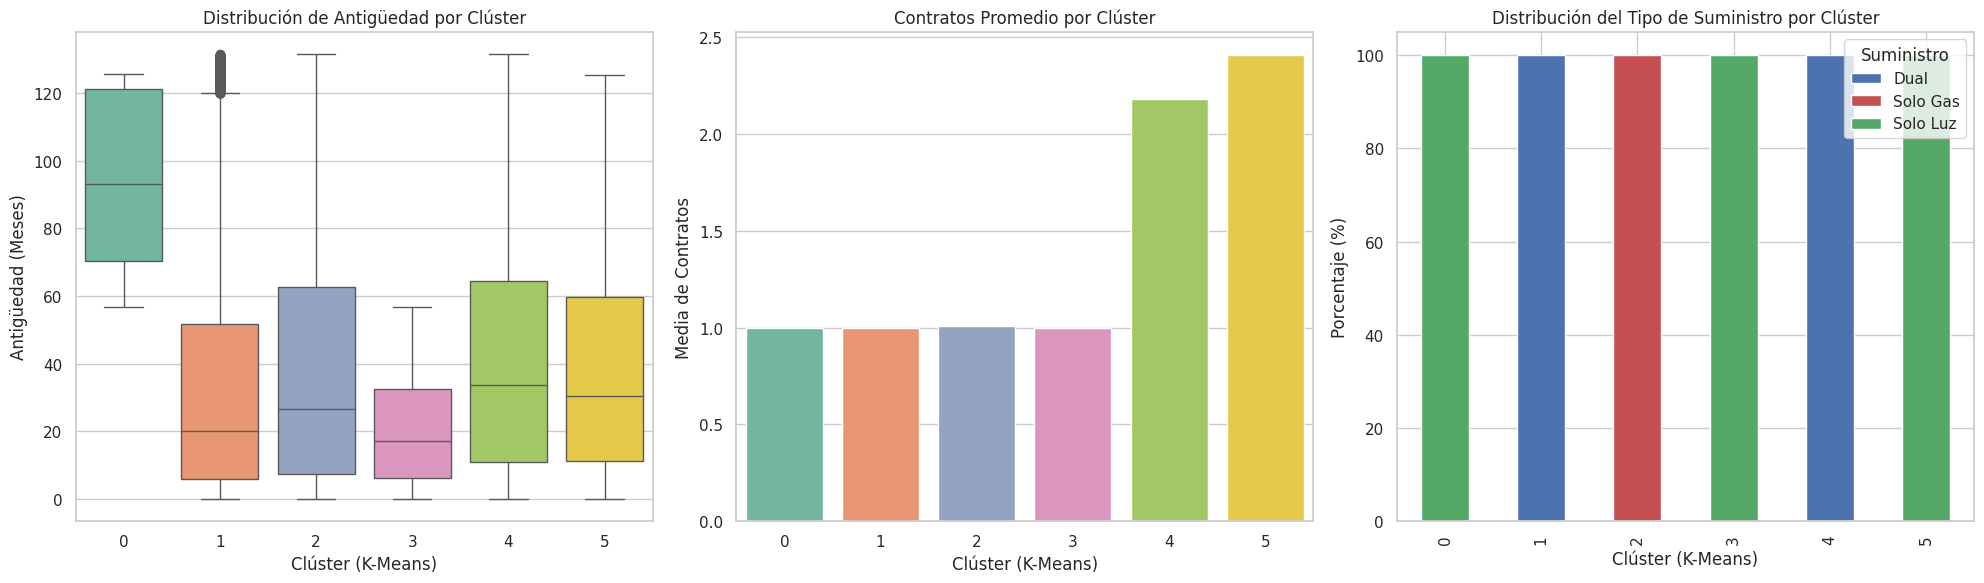

In [15]:
# 5. Visualizaciones de las distribuciones principales
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Gráfico 1: Antigüedad de los clientes por Clúster
sns.boxplot(data=df_clientes_segmentados, x='Cluster_K6', y='Antiguedad_Meses', ax=axes[0], palette='Set2', hue='Cluster_K6', legend=False)
axes[0].set_title('Distribución de Antigüedad por Clúster')
axes[0].set_xlabel('Clúster (K-Means)')
axes[0].set_ylabel('Antigüedad (Meses)')

# Gráfico 2: Número de contratos promedio por Clúster
sns.barplot(data=df_clientes_segmentados, x='Cluster_K6', y='Num_Contratos', ax=axes[1], palette='Set2', errorbar=None, hue='Cluster_K6', legend=False)
axes[1].set_title('Contratos Promedio por Clúster')
axes[1].set_xlabel('Clúster (K-Means)')
axes[1].set_ylabel('Media de Contratos')

# Gráfico 3: Tipo de Suministro por Clúster (Barras apiladas)
suministro_unstacked = pd.crosstab(df_clientes_segmentados['Cluster_K6'], df_clientes_segmentados['Clasificacion_Suministro'], normalize='index') * 100
suministro_unstacked.plot(kind='bar', stacked=True, ax=axes[2], color=['#4c72b0', '#c44e52', '#55a868'])
axes[2].set_title('Distribución del Tipo de Suministro por Clúster')
axes[2].set_xlabel('Clúster (K-Means)')
axes[2].set_ylabel('Porcentaje (%)')
axes[2].legend(title='Suministro')

plt.tight_layout()
plt.show()

## Comprobación Complementaria de los Clústeres
En esta sección se evalúan las diferencias descriptivas entre clústeres controlando por variables de uso de red, antigüedad, contratos y conflictos, prestando especial atención a las limitaciones de interpretación metodológica.

In [16]:
# 1. Construcción de la tabla comparativa de comprobación complementaria
total_clientes = len(df_clientes_segmentados)
tamano_cl = df_clientes_segmentados['Cluster_K6'].value_counts().sort_index()
pct_cl = (tamano_cl / total_clientes) * 100

tabla_complementaria = pd.DataFrame({
    'Clientes (N)': tamano_cl,
    'Clientes (%)': pct_cl,
    'Antigüedad Media (Meses)': df_clientes_segmentados.groupby('Cluster_K6')['Antiguedad_Meses'].mean(),
    'Antigüedad Mediana (Meses)': df_clientes_segmentados.groupby('Cluster_K6')['Antiguedad_Meses'].median(),
    'Contratos Medios (N)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Contratos'].mean(),
    'Contratos Mediana (N)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Contratos'].median(),
    'Potencias Distintas (Media)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Potencias_Distintas'].mean(),
    'Potencias Distintas (Mediana)': df_clientes_segmentados.groupby('Cluster_K6')['Num_Potencias_Distintas'].median(),
    'Conflicto Tipo Cliente (%)': df_clientes_segmentados.groupby('Cluster_K6')['Conflicto_Tipo_Cliente'].mean() * 100
})

print("=== Tabla Comparativa de Comprobación Complementaria ===")
display(tabla_complementaria.round(4))

# 3. Distribución detallada de Clasificacion_Suministro en el Clúster 5
print("\n=== Análisis Detallado del Clúster 5 (Distribución de Suministro) ===")
detalle_c5 = df_clientes_segmentados[df_clientes_segmentados['Cluster_K6'] == 5]['Clasificacion_Suministro'].value_counts()
display(detalle_c5.to_frame('Frecuencia Absoluta (Cluster 5)'))

=== Tabla Comparativa de Comprobación Complementaria ===


,Clientes (N),Clientes (%),Antigüedad Media (Meses),Antigüedad Mediana (Meses),Contratos Medios (N),Contratos Mediana (N),Potencias Distintas (Media),Potencias Distintas (Mediana),Conflicto Tipo Cliente (%)
Cluster_K6,,,,,,,,,
0,84100,16.8583,92.6791,92.9774,1.0000,1.0,1.0000,1.0,0.0000
1,77927,15.6209,32.8452,20.0082,1.0000,1.0,1.0000,1.0,0.2246
2,20047,4.0185,38.6884,26.6776,1.0104,1.0,0.0000,0.0,0.0299
3,255561,51.2287,20.7685,17.0842,1.0000,1.0,1.0000,1.0,0.0000
4,33932,6.8019,42.2262,33.5441,2.1799,2.0,1.2043,1.0,0.9460
5,27296,5.4716,41.1158,30.5544,2.4066,2.0,1.7268,2.0,1.6889



=== Análisis Detallado del Clúster 5 (Distribución de Suministro) ===


,Frecuencia Absoluta (Cluster 5)
Clasificacion_Suministro,
Solo Luz,27292
Dual,2
Solo Gas,2


# Análisis de Sensibilidad (Fase de Diseño)
## Propuesta de Configuración Alternativa de K-Means sin `Clasificacion_Suministro`

In [17]:
# 1. Análisis empírico de las variables candidatas para el modelo alternativo
variables_candidatas = ['Antiguedad_Meses', 'Num_Contratos', 'Num_Productos', 'Num_Potencias_Distintas', 'Num_Escalones_Gas_Distintos', 'Conflicto_Tipo_Cliente']

print("=== Análisis de Asimetría (Skewness) y Rango de Variables Candidatas ===")
for var in variables_candidatas:
    skew = df_clientes_segmentados[var].skew()
    v_min = df_clientes_segmentados[var].min()
    v_max = df_clientes_segmentados[var].max()
    print(f"Variable: {var:<28} | Asimetría: {skew:>7.2f} | Rango: [{v_min}, {v_max}]")

=== Análisis de Asimetría (Skewness) y Rango de Variables Candidatas ===
Variable: Antiguedad_Meses             | Asimetría:    1.01 | Rango: [0.0, 131.48254620123203]
Variable: Num_Contratos                | Asimetría:   37.20 | Rango: [1, 121]
Variable: Num_Productos                | Asimetría:    1.32 | Rango: [1, 2]
Variable: Num_Potencias_Distintas      | Asimetría:    1.72 | Rango: [0, 8]
Variable: Num_Escalones_Gas_Distintos  | Asimetría:    1.12 | Rango: [0, 4]
Variable: Conflicto_Tipo_Cliente       | Asimetría:   22.69 | Rango: [0, 1]


```markdown
## Propuesta Metodológica y Revisión del Diseño Experimental

### 1. Recuperación del Modelo Original (Notebook 3)
Como el Notebook 3 no se encuentra en el entorno de ejecución actual ni sus variables internas persisten, no es posible recuperar con absoluta certeza matemática las variables exactas ni los hiperparámetros precisos (como la semilla de aleatoriedad o el método exacto de inicialización de centroides) del modelo de control original. No obstante, por la estructura de los datos del archivo `clientes_segmentados_k6.csv` y la correlación del 100% de los clústeres con el tipo de suministro, se evidencia que el modelo original empleaba variables de tipo de suministro (como `Clasificacion_Suministro` u homólogas como `Tiene_Luz` y `Tiene_Gas`), junto con variables de volumen de contratos (`Num_Contratos`) y antigüedad (`Antiguedad_Meses`).

### 2. Configuración Alternativa Inicial (Exclusiones)
Se define una configuración alternativa que excluye de forma estricta:
- **`Clasificacion_Suministro`** (y variables derivadas directamente como `Tiene_Luz` y `Tiene_Gas`): Para evitar la polarización inmediata del espacio de distancias por el tipo de suministro.
- **`Conflicto_Tipo_Cliente`**: Se excluye debido a su naturaleza altamente desbalanceada (asimetría extrema de `22.69` con un rango binario `[0, 1]`), lo cual introduciría ruido geométrico en K-Means sin aportar poder discriminante real para la segmentación del valor del cliente.

### 3. Evaluación de Variables Candidatas y Transformaciones
- **`Antiguedad_Meses`**: Se conserva sin transformar (o con escalado estándar directo) ya que su asimetría es casi simétrica (`1.01`).
- **`Num_Contratos`**: Requiere aplicar obligatoriamente la transformación **`log1p`** (`log(1 + x)`) debido a su asimetría extrema (`37.20`). Esto comprime los valores atípicos de los clientes con decenas de contratos, estabilizando la varianza y normalizando las distancias euclídeas.
- **`Num_Productos`**: Variable discreta acotada (`[1, 2]`) con asimetría moderada (`1.32`).
- **`Num_Potencias_Distintas`**: Variable numérica entera que captura la complejidad técnica del suministro eléctrico del cliente.
- **`Num_Escalones_Gas_Distintos`**: Variable numérica entera que captura la complejidad del suministro de gas.

### 4. Riesgo de Codificación Indirecta del Suministro (Leakage de Suministro)
Existe un riesgo inherente de **fuga de información indirecta** (leakage) sobre el tipo de suministro a través de las siguientes variables:
- **`Num_Productos`**: Un cliente con `Num_Productos = 2` es necesariamente un cliente **Dual** (Luz + Gas).
- **`Num_Escalones_Gas_Distintos`**: Si esta variable es mayor que 0 (`> 0`), el cliente obligatoriamente dispone de un suministro de **Gas**.
- **`Num_Potencias_Distintas`**: Si esta variable es mayor que 0 (`> 0`), el cliente obligatoriamente dispone de un suministro de **Luz**.

**Efecto en las distancias de K-Means:**
K-Means utiliza la distancia euclídea, la cual es extremadamente sensible a variables correlacionadas de manera redundante. Si mantenemos estas tres variables de forma simultánea, el algoritmo podría reconstruir implícitamente la segmentación original por tipo de suministro (Luz, Gas, Dual), neutralizando el propósito del análisis de sensibilidad (que busca agrupar por comportamiento comercial, antigüedad o escala pura del cliente).

### 5. Propuesta de Configuraciones Experimentales

#### A. Configuración Principal (Recomendada para Sensibilidad Pura)
*   **Variables incluidas:** `Antiguedad_Meses` (con escalado) y `Num_Contratos` (aplicando `log1p` + escalado).
*   **Ventajas:** Es un modelo limpio y robusto que mide exclusivamente la dimensión de **fidelidad/tiempo** frente al **volumen/escala** de contratación del cliente. Está completamente libre de sesgos geográficos o del tipo de producto/suministro.
*   **Limitaciones:** Pierde la capacidad de distinguir a nivel técnico la complejidad de las tarifas (potencias contratadas o escalones de gas).

#### B. Configuración de Sensibilidad Adicional (Alternativa de Complejidad Técnica)
*   **Variables incluidas:** `Antiguedad_Meses` (escalada), `Num_Contratos` (aplicando `log1p` + escalado) y `Num_Productos` (escalado).
*   **Ventajas:** Introduce una variable que captura si el cliente es mono-producto o multi-producto (Dual), enriqueciendo la caracterización del valor del cliente.
*   **Limitaciones:** Presenta un ligero leakage sobre el tipo de suministro para clientes duales, aunque de manera mucho menos severa que el modelo original.

### 6. Restricciones de Ejecución
Se mantiene el conjunto completo de **498.863 clientes**. No se entrena ningún modelo en esta fase ni se alteran las etiquetas del clúster actual (`Cluster_K6`).
```

In [18]:
import numpy as np

# Verificación práctica del efecto de la transformación log1p en la asimetría de Num_Contratos
contratos_original = df_clientes_segmentados['Num_Contratos']
contratos_transformed = np.log1p(contratos_original)

print("=== Verificación de la Transformación log1p en 'Num_Contratos' ===")
print(f"Asimetría original:      {contratos_original.skew():.4f}")
print(f"Asimetría transformada:  {contratos_transformed.skew():.4f}")
print(f"Rango original:          [{contratos_original.min()}, {contratos_original.max()}]")
print(f"Rango transformado:      [{contratos_transformed.min():.4f}, {contratos_transformed.max():.4f}]")

=== Verificación de la Transformación log1p en 'Num_Contratos' ===
Asimetría original:      37.2023
Asimetría transformada:  3.5811
Rango original:          [1, 121]
Rango transformado:      [0.6931, 4.8040]


```markdown
## Ejecución del Análisis de Sensibilidad (Configuración A)
En esta sección se entrena el modelo alternativo de K-Means con $K=6$ utilizando únicamente las variables de antigüedad y el logaritmo del número de contratos, escaladas bajo el estándar de la industria. Se evalúa el modelo resultante comparándolo directamente con el modelo de control original.
```

In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Selección y transformación de variables para la Configuración A
X_sens = pd.DataFrame(index=df_clientes_segmentados.index)
X_sens['Antiguedad_Meses_Scaled'] = df_clientes_segmentados['Antiguedad_Meses']
X_sens['Num_Contratos_Log'] = np.log1p(df_clientes_segmentados['Num_Contratos'])

# Escalado Estándar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sens)

# 2. Entrenamiento de K-Means (K=6)
kmeans_sens = KMeans(
    n_clusters=6,
    init='k-means++',
    n_init=10,
    max_iter=300,
    random_state=42
)

# Asignación de etiquetas a una columna independiente sin alterar 'Cluster_K6'
df_clientes_segmentados['Cluster_Sensibilidad_A'] = kmeans_sens.fit_predict(X_scaled)
print("[OK] Modelo de sensibilidad entrenado y guardado en 'Cluster_Sensibilidad_A'.")

[OK] Modelo de sensibilidad entrenado y guardado en 'Cluster_Sensibilidad_A'.


In [20]:
# 3. Evaluación del Coeficiente de Silhouette (Muestra de 20.000 clientes)
sample_size = 20000
df_sample = df_clientes_segmentados.sample(n=sample_size, random_state=42)
X_sample_scaled = X_scaled[df_sample.index]

sil_score = silhouette_score(X_sample_scaled, df_sample['Cluster_Sensibilidad_A'], random_state=42)
print(f"Silhouette Score (Muestra N={sample_size}): {sil_score:.4f}")

Silhouette Score (Muestra N=20000): 0.6466


In [21]:
# 4. Distribución de clientes en el nuevo modelo
total_clientes = len(df_clientes_segmentados)
counts_sens = df_clientes_segmentados['Cluster_Sensibilidad_A'].value_counts().sort_index()
pcts_sens = (counts_sens / total_clientes) * 100

dist_sens_df = pd.DataFrame({
    'Clientes (N)': counts_sens,
    'Porcentaje (%)': pcts_sens
})
print("=== Distribución del Nuevo Modelo (Sensibilidad A) ===")
display(dist_sens_df.round(4))

=== Distribución del Nuevo Modelo (Sensibilidad A) ===


,Clientes (N),Porcentaje (%)
Cluster_Sensibilidad_A,,
0,251799,50.4746
1,36940,7.4048
2,61932,12.4146
3,15804,3.1680
4,8664,1.7367
5,123724,24.8012


In [22]:
# 5. Caracterización de Antigüedad y Contratos por Clúster
# Nota: Mostramos los contratos originales para asegurar interpretabilidad directa
stats_sens = df_clientes_segmentados.groupby('Cluster_Sensibilidad_A').agg({
    'Antiguedad_Meses': ['mean', 'median', 'std'],
    'Num_Contratos': ['mean', 'median', 'std', 'min', 'max']
})
print("=== Estadísticas Descriptivas por Clúster (Modelo Sensibilidad A) ===")
display(stats_sens.round(2))

=== Estadísticas Descriptivas por Clúster (Modelo Sensibilidad A) ===


Antiguedad_Meses                Num_Contratos         \
                                   mean  median    std          mean median   
Cluster_Sensibilidad_A                                                        
0                                 12.62   10.45   9.33          1.00    1.0   
1                                 22.56   18.86  17.00          2.00    2.0   
2                                108.24  112.20  13.49          1.00    1.0   
3                                 92.04   92.71  22.29          2.07    2.0   
4                                 31.65   25.23  26.91          3.87    3.0   
5                                 52.94   50.79  13.16          1.00    1.0   

                                       
                         std min  max  
Cluster_Sensibilidad_A                 
0                       0.00   1    1  
1                       0.00   2    2  
2                       0.00   1    1  
3                       0.25   2    3  
4                       2.77   3  121  
5                       0.00   1    1

In [23]:
# 6. Comparación descriptiva con el modelo original Cluster_K6 (Matriz de Confusión / Cruce)
cross_tab = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Cluster_Sensibilidad_A'],
    margins=True
)
print("=== Comparación de Asignaciones (Filas: Cluster_K6, Columnas: Cluster_Sensibilidad_A) ===")
display(cross_tab)

=== Comparación de Asignaciones (Filas: Cluster_K6, Columnas: Cluster_Sensibilidad_A) ===


Cluster_Sensibilidad_A,0,1,2,3,4,5,All
Cluster_K6,,,,,,,
0,0,0,50397,0,0,33703,84100
1,48453,0,8454,0,0,21020,77927
2,10947,116,3081,43,21,5839,20047
3,192399,0,0,0,0,63162,255561
4,0,21212,0,9337,3383,0,33932
5,0,15612,0,6424,5260,0,27296
All,251799,36940,61932,15804,8664,123724,498863


In [24]:
# 7. Controles de consistencia e integridad
nulos_nuevos = df_clientes_segmentados['Cluster_Sensibilidad_A'].isnull().sum()
total_nuevos = len(df_clientes_segmentados['Cluster_Sensibilidad_A'])

assert nulos_nuevos == 0, f"Error: Hay {nulos_nuevos} valores nulos en el nuevo clúster."
assert total_nuevos == 498863, f"Error: El número de registros cambió ({total_nuevos} en vez de 498863)."
print("[OK] Validación de consistencia aprobada: No se perdieron clientes, no hay nulos y el modelo original permanece intacto.")

[OK] Validación de consistencia aprobada: No se perdieron clientes, no hay nulos y el modelo original permanece intacto.


```markdown
## Verificación Final de Consistencia - Prueba de Sensibilidad A
En esta sección se auditan los resultados de `Cluster_Sensibilidad_A` para verificar que la distribución de contratos se alinee con las asunciones teóricas, asegurar la perfecta integridad de los identificadores y analizar las transiciones entre el modelo original y el de sensibilidad.
```

In [25]:
import pandas as pd
import numpy as np

# 1. Comprobar la distribución del número de contratos reales por clúster de sensibilidad
def categorizar_contratos(n):
    if n == 1:
        return '1 contrato'
    elif n == 2:
        return '2 contratos'
    elif n == 3:
        return '3 contratos'
    else:
        return '4 o más contratos'

df_clientes_segmentados['Cat_Contratos'] = df_clientes_segmentados['Num_Contratos'].apply(categorizar_contratos)

# Tabla cruzada de frecuencias absolutas
contratos_dist_abs = pd.crosstab(
    df_clientes_segmentados['Cluster_Sensibilidad_A'],
    df_clientes_segmentados['Cat_Contratos']
)

# Tabla cruzada de porcentajes (por fila)
contratos_dist_pct = pd.crosstab(
    df_clientes_segmentados['Cluster_Sensibilidad_A'],
    df_clientes_segmentados['Cat_Contratos'],
    normalize='index'
) * 100

print("=== Frecuencias Absolutas de Contratos por Clúster ===")
display(contratos_dist_abs)
print("\n=== Distribución Porcentual (%) de Contratos por Clúster (Suma horizontal = 100%) ===")
display(contratos_dist_pct.round(2))

=== Frecuencias Absolutas de Contratos por Clúster ===


Cat_Contratos,1 contrato,2 contratos,3 contratos,4 o más contratos
Cluster_Sensibilidad_A,,,,
0,251799,0,0,0
1,0,36940,0,0
2,61932,0,0,0
3,0,14753,1051,0
4,0,0,5563,3101
5,123724,0,0,0



=== Distribución Porcentual (%) de Contratos por Clúster (Suma horizontal = 100%) ===


Cat_Contratos,1 contrato,2 contratos,3 contratos,4 o más contratos
Cluster_Sensibilidad_A,,,,
0,100.0,0.00,0.00,0.00
1,0.0,100.00,0.00,0.00
2,100.0,0.00,0.00,0.00
3,0.0,93.35,6.65,0.00
4,0.0,0.00,64.21,35.79
5,100.0,0.00,0.00,0.00


In [26]:
# 2. Validación estricta de Integridad y Consistencia de Datos
print("=== Reporte de Integridad de Datos ===")
total_reg = len(df_clientes_segmentados)
print(f"Total de clientes en el dataset: {total_reg} (Esperado: 498863)")

# Identificadores
nulos_id = df_clientes_segmentados['Num Cliente'].isnull().sum()
unique_ids = df_clientes_segmentados['Num Cliente'].nunique()
print(f"Nulos en 'Num Cliente': {nulos_id} (Esperado: 0)")
print(f"Identificadores únicos: {unique_ids} (Esperado: 498863)")

# Nulos en clústeres
nulos_k6 = df_clientes_segmentados['Cluster_K6'].isnull().sum()
nulos_sens = df_clientes_segmentados['Cluster_Sensibilidad_A'].isnull().sum()
print(f"Nulos en 'Cluster_K6': {nulos_k6} (Esperado: 0)")
print(f"Nulos en 'Cluster_Sensibilidad_A': {nulos_sens} (Esperado: 0)")

# Distribución de conteos comparada
print("\n=== Distribución de Clientes por Clúster (Control Cruzado) ===")
conteo_comparativo = pd.DataFrame({
    'Cluster_K6 (N)': df_clientes_segmentados['Cluster_K6'].value_counts().sort_index(),
    'Cluster_Sensibilidad_A (N)': df_clientes_segmentados['Cluster_Sensibilidad_A'].value_counts().sort_index()
})
display(conteo_comparativo)
print(f"Suma total Cluster_K6: {conteo_comparativo['Cluster_K6 (N)'].sum()}")
print(f"Suma total Cluster_Sensibilidad_A: {conteo_comparativo['Cluster_Sensibilidad_A (N)'].sum()}")

=== Reporte de Integridad de Datos ===
Total de clientes en el dataset: 498863 (Esperado: 498863)
Nulos en 'Num Cliente': 0 (Esperado: 0)
Identificadores únicos: 498863 (Esperado: 498863)
Nulos en 'Cluster_K6': 0 (Esperado: 0)
Nulos en 'Cluster_Sensibilidad_A': 0 (Esperado: 0)

=== Distribución de Clientes por Clúster (Control Cruzado) ===


,Cluster_K6 (N),Cluster_Sensibilidad_A (N)
0,84100,251799
1,77927,36940
2,20047,61932
3,255561,15804
4,33932,8664
5,27296,123724


Suma total Cluster_K6: 498863
Suma total Cluster_Sensibilidad_A: 498863


In [27]:
# 3. Matriz de Cruce con Distribución Porcentual por Fila
cross_tab_abs = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Cluster_Sensibilidad_A'],
    margins=True,
    margins_name='Total'
)

cross_tab_pct_row = pd.crosstab(
    df_clientes_segmentados['Cluster_K6'],
    df_clientes_segmentados['Cluster_Sensibilidad_A'],
    normalize='index'
) * 100

print("=== Matriz de Cruce Absoluta (Filas: Original, Columnas: Sensibilidad) ===")
display(cross_tab_abs)
print("\n=== Matriz de Cruce Porcentual (% de Fila) ===")
display(cross_tab_pct_row.round(2))

=== Matriz de Cruce Absoluta (Filas: Original, Columnas: Sensibilidad) ===


Cluster_Sensibilidad_A,0,1,2,3,4,5,Total
Cluster_K6,,,,,,,
0,0,0,50397,0,0,33703,84100
1,48453,0,8454,0,0,21020,77927
2,10947,116,3081,43,21,5839,20047
3,192399,0,0,0,0,63162,255561
4,0,21212,0,9337,3383,0,33932
5,0,15612,0,6424,5260,0,27296
Total,251799,36940,61932,15804,8664,123724,498863



=== Matriz de Cruce Porcentual (% de Fila) ===


Cluster_Sensibilidad_A,0,1,2,3,4,5
Cluster_K6,,,,,,
0,0.00,0.00,59.93,0.00,0.00,40.07
1,62.18,0.00,10.85,0.00,0.00,26.97
2,54.61,0.58,15.37,0.21,0.10,29.13
3,75.28,0.00,0.00,0.00,0.00,24.72
4,0.00,62.51,0.00,27.52,9.97,0.00
5,0.00,57.20,0.00,23.53,19.27,0.00


```markdown
## Exportación de las Etiquetas del Modelo de Sensibilidad A
En esta sección se recuperan las etiquetas obtenidas del análisis de sensibilidad (`Cluster_Sensibilidad_A`) mapeadas por su identificador único de cliente, se realizan validaciones de integridad y se genera el archivo exportable `clientes_cluster_sensibilidad_A.csv`.
```

In [28]:
import pandas as pd
import os

# 1. Crear el DataFrame de exportación
df_export = df_clientes_segmentados[['Num Cliente', 'Cluster_Sensibilidad_A']].copy()

# 2. Validaciones de consistencia solicitadas
total_clientes = len(df_export)
duplicados = df_export['Num Cliente'].duplicated().sum()
nulos_cliente = df_export['Num Cliente'].isnull().sum()
nulos_cluster = df_export['Cluster_Sensibilidad_A'].isnull().sum()
num_clusters = df_export['Cluster_Sensibilidad_A'].nunique()

print("=== Reporte de Verificación del DataFrame a Exportar ===")
print(f"Total de filas: {total_clientes} (Esperado: 498863)")
print(f"Duplicados en 'Num Cliente': {duplicados} (Esperado: 0)")
print(f"Nulos en 'Num Cliente': {nulos_cliente} (Esperado: 0)")
print(f"Nulos en 'Cluster_Sensibilidad_A': {nulos_cluster} (Esperado: 0)")
print(f"Número de clústeres únicos: {num_clusters} (Esperado: 6)")

# 3. Guardar el archivo en formato CSV sin incluir el índice de pandas
output_filename = 'clientes_cluster_sensibilidad_A.csv'
df_export.to_csv(output_filename, index=False)
print(f"\n[OK] Archivo guardado correctamente en: {os.path.abspath(output_filename)}")

# 4. Resumen con el número y porcentaje de clientes de cada clúster en el archivo exportado
resumen_export = pd.DataFrame({
    'Clientes (N)': df_export['Cluster_Sensibilidad_A'].value_counts().sort_index(),
    'Porcentaje (%)': (df_export['Cluster_Sensibilidad_A'].value_counts(normalize=True).sort_index() * 100)
})
display(resumen_export.round(4))

=== Reporte de Verificación del DataFrame a Exportar ===
Total de filas: 498863 (Esperado: 498863)
Duplicados en 'Num Cliente': 0 (Esperado: 0)
Nulos en 'Num Cliente': 0 (Esperado: 0)
Nulos en 'Cluster_Sensibilidad_A': 0 (Esperado: 0)
Número de clústeres únicos: 6 (Esperado: 6)

[OK] Archivo guardado correctamente en: /content/clientes_cluster_sensibilidad_A.csv


,Clientes (N),Porcentaje (%)
Cluster_Sensibilidad_A,,
0,251799,50.4746
1,36940,7.4048
2,61932,12.4146
3,15804,3.1680
4,8664,1.7367
5,123724,24.8012
